In [1]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import torch
from torch import nn
from torch.utils.data import Dataset, DataLoader

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("PyTorch:", torch.__version__)
print("Device:", DEVICE)

PyTorch: 2.14.1+cpu
Device: cpu


In [2]:
DATA_FILE = Path.cwd() / "daily_tourism_demand_forecasting_2000_2015.csv"

print("Current working directory:", Path.cwd())
print("Looking for:", DATA_FILE)

if not DATA_FILE.exists():
    raise FileNotFoundError(
        f"Cannot find {DATA_FILE.name} in {Path.cwd()}. "
        "Move the CSV into the same folder as the notebook, "
        "or edit DATA_FILE to its full path."
    )

raw = pd.read_csv(DATA_FILE)

print("Loaded:", DATA_FILE.name)
print("Shape:", raw.shape)
print("Columns:", list(raw.columns))
display(raw.head())

Current working directory: D:\Coding\thesis
Looking for: D:\Coding\thesis\daily_tourism_demand_forecasting_2000_2015.csv
Loaded: daily_tourism_demand_forecasting_2000_2015.csv
Shape: (29220, 8)
Columns: ['Date', 'Destination', 'Visitor_Count', 'Hotel_Occupancy', 'Flight_Arrivals', 'Average_Temperature', 'Economic_Index', 'Major_Event']


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Paris,152,91.861719,34,24.279758,1.098658,Festival
1,2000-01-01,Tokyo,152,77.833310,94,13.369956,0.833709,Festival
2,2000-01-01,New York,153,88.322903,41,-2.743537,1.221999,Festival
3,2000-01-01,London,207,68.493564,83,34.688462,1.117482,Exhibition
4,2000-01-01,Berlin,107,80.990257,68,15.990986,0.899861,Exhibition


In [3]:
print("Column names:")
print(raw.columns.tolist())

print("\nData types:")
display(raw.dtypes.to_frame("dtype"))

print("\nMissing values:")
display(raw.isna().sum().to_frame("missing_count"))

print("\nDataset information:")
raw.info()

Column names:
['Date', 'Destination', 'Visitor_Count', 'Hotel_Occupancy', 'Flight_Arrivals', 'Average_Temperature', 'Economic_Index', 'Major_Event']

Data types:


,dtype
Date,object
Destination,object
Visitor_Count,int64
Hotel_Occupancy,float64
Flight_Arrivals,int64
Average_Temperature,float64
Economic_Index,float64
Major_Event,object



Missing values:


,missing_count
Date,0
Destination,0
Visitor_Count,0
Hotel_Occupancy,0
Flight_Arrivals,0
Average_Temperature,0
Economic_Index,0
Major_Event,5870



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 29220 entries, 0 to 29219
Data columns (total 8 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   Date                 29220 non-null  object 
 1   Destination          29220 non-null  object 
 2   Visitor_Count        29220 non-null  int64  
 3   Hotel_Occupancy      29220 non-null  float64
 4   Flight_Arrivals      29220 non-null  int64  
 5   Average_Temperature  29220 non-null  float64
 6   Economic_Index       29220 non-null  float64
 7   Major_Event          23350 non-null  object 
dtypes: float64(3), int64(2), object(3)
memory usage: 1.8+ MB


In [4]:
TIME_COL = "Date"
TARGET_COL = "Visitor_Count"
DESTINATION_COL = "Destination"

# ตรวจสอบเมืองที่มีในชุดข้อมูล
print("Destinations:")
print(sorted(raw[DESTINATION_COL].dropna().unique()))

# เลือกเมืองสำหรับการทดลองครั้งแรก
SELECTED_DESTINATION = "Paris"

data = raw.copy()

data[TIME_COL] = pd.to_datetime(
    data[TIME_COL],
    errors="raise"
)

# กรองข้อมูลให้เหลือเฉพาะเมืองที่เลือก
data = data[
    data[DESTINATION_COL] == SELECTED_DESTINATION
].copy()

# เรียงข้อมูลตามวันที่
data = data.sort_values(TIME_COL).reset_index(drop=True)

print("Selected destination:", SELECTED_DESTINATION)
print("Number of rows:", len(data))
print("Date range:", data[TIME_COL].min(), "to", data[TIME_COL].max())

display(data.head(20))

Destinations:
['Berlin', 'London', 'New York', 'Paris', 'Tokyo']
Selected destination: Paris
Number of rows: 5844
Date range: 2000-01-01 00:00:00 to 2015-12-31 00:00:00


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Paris,152,91.861719,34,24.279758,1.098658,Festival
1,2000-01-02,Paris,269,98.950221,34,13.242799,1.285176,Conference
2,2000-01-03,Paris,84,96.372816,55,2.289444,1.255361,Festival
3,2000-01-04,Paris,237,81.707843,60,6.850940,0.665267,Exhibition
4,2000-01-05,Paris,86,89.184247,54,13.888597,0.619594,NaN
5,2000-01-06,Paris,209,83.954619,47,32.187906,1.308120,Conference
6,2000-01-07,Paris,221,69.765021,78,7.928117,1.018791,Exhibition
7,2000-01-08,Paris,252,74.786178,36,24.128654,0.867783,Festival
8,2000-01-09,Paris,153,65.500838,76,-0.461059,1.424694,NaN
9,2000-01-10,Paris,165,63.365599,91,26.413626,1.168988,Festival


In [5]:
print("Duplicate dates:", data[TIME_COL].duplicated().sum())

print("\nMissing values:")
display(data.isna().sum().to_frame("missing_count"))

print("\nDate interval counts:")
display(
    data[TIME_COL]
    .diff()
    .value_counts()
    .head(10)
    .to_frame("count")
)

Duplicate dates: 0

Missing values:


,missing_count
Date,0
Destination,0
Visitor_Count,0
Hotel_Occupancy,0
Flight_Arrivals,0
Average_Temperature,0
Economic_Index,0
Major_Event,1175



Date interval counts:


,count
Date,
1 days,5843


In [6]:
series = pd.to_numeric(
    data[TARGET_COL],
    errors="coerce"
)

series = series.replace(
    [np.inf, -np.inf],
    np.nan
)

if series.isna().any():
    raise ValueError(
        "Visitor_Count มีค่าว่างหรือค่าที่ไม่ใช่ตัวเลข "
        "กรุณาตรวจสอบข้อมูลก่อนฝึกโมเดล"
    )

values = series.to_numpy(dtype=np.float32)

print("Target:", TARGET_COL)
print("Destination:", SELECTED_DESTINATION)
print("Observations:", len(values))
print(series.describe())

Target: Visitor_Count
Destination: Paris
Observations: 5844
count    5844.000000
mean      174.416667
std        72.314567
min        50.000000
25%       112.000000
50%       173.000000
75%       238.000000
max       299.000000
Name: Visitor_Count, dtype: float64


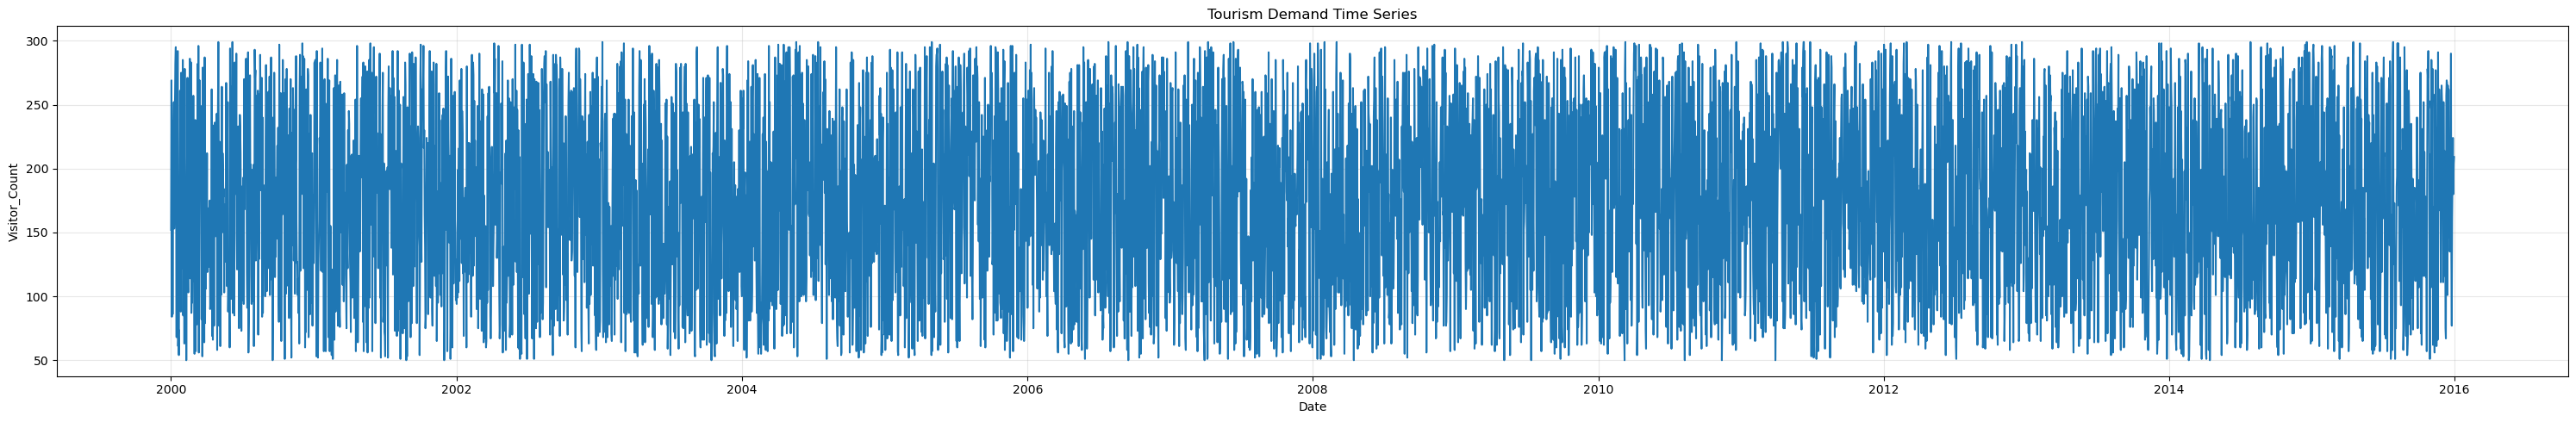

In [7]:
plt.figure(figsize=(30, 5))

if TIME_COL is not None:
    plt.plot(data[TIME_COL], values)
    plt.xlabel("Date")
else:
    plt.plot(values)
    plt.xlabel("Time step")

plt.ylabel(TARGET_COL)
plt.title("Tourism Demand Time Series")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
LOOKBACK = 30
HORIZON = 1

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

n = len(values)

train_end = int(n * TRAIN_FRAC)
val_end = int(n * (TRAIN_FRAC + VAL_FRAC))

if train_end <= LOOKBACK + HORIZON:
    raise ValueError(
        "ข้อมูล Train สั้นเกินไป "
        "กรุณาลด LOOKBACK หรือเพิ่มข้อมูล"
    )

if val_end <= train_end or n <= val_end:
    raise ValueError(
        "ข้อมูลไม่เพียงพอสำหรับแบ่ง Train/Validation/Test"
    )

print("Total observations:", n)
print("Train:", 0, "to", train_end - 1)
print("Validation:", train_end, "to", val_end - 1)
print("Test:", val_end, "to", n - 1)

Total observations: 5844
Train: 0 to 4089
Validation: 4090 to 4966
Test: 4967 to 5843


In [9]:
scaler = StandardScaler()

scaler.fit(
    values[:train_end].reshape(-1, 1)
)

scaled = scaler.transform(
    values.reshape(-1, 1)
).astype(np.float32).ravel()

print("Scaler mean:", scaler.mean_[0])
print("Scaler scale:", scaler.scale_[0])

Scaler mean: 173.7638141809291
Scaler scale: 72.35491484903729


In [10]:
def make_windows(
    arr,
    start_target,
    end_target,
    lookback,
    horizon
):
    X, y, target_indices = [], [], []

    for target_start in range(
        start_target,
        end_target - horizon + 1
    ):
        x_start = target_start - lookback
        x_end = target_start

        if x_start < 0:
            continue

        X.append(arr[x_start:x_end])

        y.append(
            arr[target_start:target_start + horizon]
        )

        target_indices.append(target_start)

    X = np.asarray(
        X, dtype=np.float32
    ).reshape(-1, lookback, 1)

    y = np.asarray(
        y, dtype=np.float32
    ).reshape(-1, horizon)

    return X, y, np.asarray(target_indices)


X_train, y_train, idx_train = make_windows(
    scaled, LOOKBACK, train_end, LOOKBACK, HORIZON
)

X_val, y_val, idx_val = make_windows(
    scaled, train_end, val_end, LOOKBACK, HORIZON
)

X_test, y_test, idx_test = make_windows(
    scaled, val_end, n, LOOKBACK, HORIZON
)

print("X_train:", X_train.shape)
print("y_train:", y_train.shape)

print("X_val:", X_val.shape)
print("y_val:", y_val.shape)

print("X_test:", X_test.shape)
print("y_test:", y_test.shape)

X_train: (4060, 30, 1)
y_train: (4060, 1)
X_val: (877, 30, 1)
y_val: (877, 1)
X_test: (877, 30, 1)
y_test: (877, 1)


In [11]:
class WindowDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(
            X, dtype=torch.float32
        )
        self.y = torch.tensor(
            y, dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):
        return self.X[index], self.y[index]


BATCH_SIZE = 32

train_loader = DataLoader(
    WindowDataset(X_train, y_train),
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    WindowDataset(X_val, y_val),
    batch_size=BATCH_SIZE,
    shuffle=False
)

In [12]:
class LSTMForecaster(nn.Module):
    def __init__(
        self,
        input_size=1,
        hidden_size=64,
        num_layers=2,
        dropout=0.2,
        horizon=1
    ):
        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0.0
        )

        self.dropout = nn.Dropout(dropout)

        self.head = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):
        output, (h_n, c_n) = self.lstm(x)

        # ใช้ hidden representation ของ time step สุดท้าย
        last_hidden = output[:, -1, :]

        return self.head(
            self.dropout(last_hidden)
        )


model = LSTMForecaster(
    input_size=1,
    hidden_size=64,
    num_layers=2,
    dropout=0.2,
    horizon=HORIZON
).to(DEVICE)

print(model)

LSTMForecaster(
  (lstm): LSTM(1, 64, num_layers=2, batch_first=True, dropout=0.2)
  (dropout): Dropout(p=0.2, inplace=False)
  (head): Linear(in_features=64, out_features=1, bias=True)
)


In [13]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=0.001
)


def evaluate_loss(model, loader):
    model.eval()
    losses = []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(DEVICE)
            yb = yb.to(DEVICE)

            pred = model(xb)
            loss = criterion(pred, yb)

            losses.append(loss.item())

    return float(np.mean(losses)) if losses else np.nan

In [14]:
EPOCHS = 100
PATIENCE = 12

best_val_loss = float("inf")
best_state = None
patience_counter = 0

history = {
    "train": [],
    "val": []
}

for epoch in range(1, EPOCHS + 1):

    model.train()
    train_losses = []

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()

        pred = model(xb)
        loss = criterion(pred, yb)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        train_losses.append(loss.item())

    train_loss = float(np.mean(train_losses))
    val_loss = evaluate_loss(model, val_loader)

    history["train"].append(train_loss)
    history["val"].append(val_loss)

    if val_loss < best_val_loss:
        best_val_loss = val_loss

        best_state = {
            key: value.detach().cpu().clone()
            for key, value in model.state_dict().items()
        }

        patience_counter = 0
    else:
        patience_counter += 1

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:03d} | "
            f"Train MSE: {train_loss:.5f} | "
            f"Val MSE: {val_loss:.5f}"
        )

    if patience_counter >= PATIENCE:
        print("Early stopping at epoch", epoch)
        break


if best_state is not None:
    model.load_state_dict(best_state)

Epoch 001 | Train MSE: 0.99893 | Val MSE: 1.00120
Epoch 010 | Train MSE: 1.00059 | Val MSE: 0.98230
Epoch 020 | Train MSE: 0.99881 | Val MSE: 0.98528
Early stopping at epoch 20


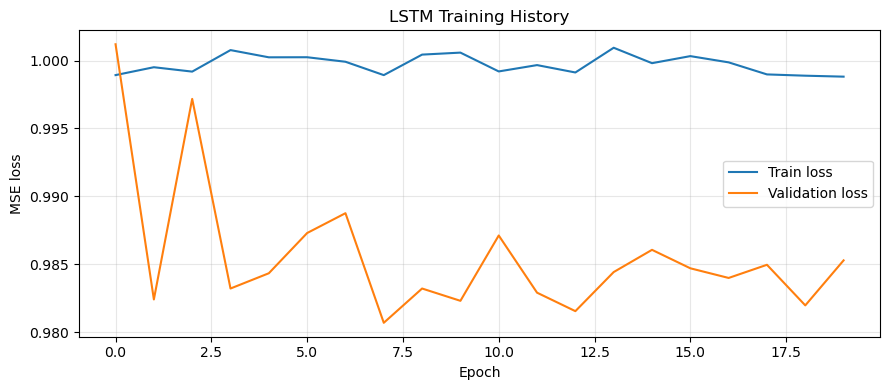

In [15]:
plt.figure(figsize=(9, 4))

plt.plot(history["train"], label="Train loss")
plt.plot(history["val"], label="Validation loss")

plt.xlabel("Epoch")
plt.ylabel("MSE loss")
plt.title("LSTM Training History")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [16]:
model.eval()

with torch.no_grad():
    X_test_tensor = torch.tensor(
        X_test,
        dtype=torch.float32,
        device=DEVICE
    )

    pred_scaled = model(
        X_test_tensor
    ).cpu().numpy()


# แปลงค่ากลับไปเป็นหน่วยเดิม
y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).reshape(y_test.shape)

pred_original = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).reshape(pred_scaled.shape)

print("Actual shape:", y_test_original.shape)
print("Prediction shape:", pred_original.shape)

Actual shape: (877, 1)
Prediction shape: (877, 1)


In [17]:
def smape(y_true, y_pred, eps=1e-8):
    denominator = (
        np.abs(y_true) + np.abs(y_pred) + eps
    )

    return np.mean(
        2 * np.abs(y_pred - y_true) / denominator
    ) * 100


actual = y_test_original.ravel()
predicted = pred_original.ravel()

mae = mean_absolute_error(
    actual, predicted
)

rmse = np.sqrt(
    mean_squared_error(actual, predicted)
)

smape_value = smape(
    actual, predicted
)

metrics = pd.DataFrame({
    "Metric": ["MAE", "RMSE", "sMAPE (%)"],
    "Value": [mae, rmse, smape_value]
})

display(metrics)

,Metric,Value
0,MAE,63.569626
1,RMSE,73.006083
2,sMAPE (%),38.963902


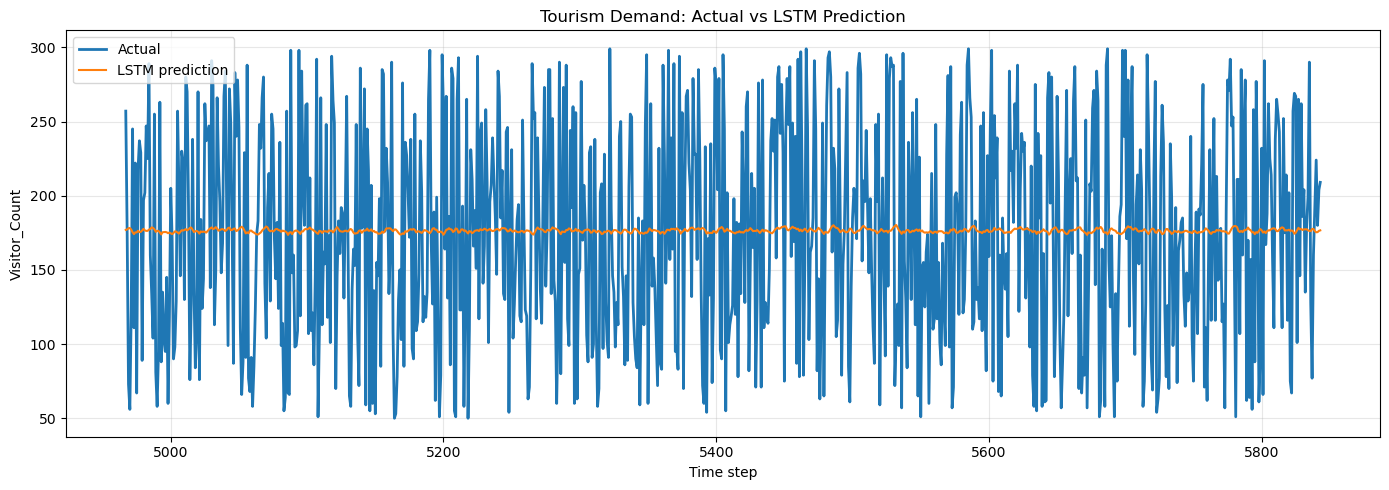

In [18]:
if HORIZON != 1:
    raise ValueError(
        "กราฟนี้ออกแบบสำหรับ HORIZON = 1"
    )

plt.figure(figsize=(14, 5))

plt.plot(
    idx_test,
    values[idx_test],
    label="Actual",
    linewidth=2
)

plt.plot(
    idx_test,
    pred_original[:, 0],
    label="LSTM prediction",
    linewidth=1.5
)

plt.xlabel("Time step")
plt.ylabel(TARGET_COL)
plt.title("Tourism Demand: Actual vs LSTM Prediction")

plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [19]:
# Baseline: ทำนายว่าค่าถัดไปเท่ากับค่าล่าสุด
baseline_scaled = X_test[:, -1, 0]

baseline_original = scaler.inverse_transform(
    baseline_scaled.reshape(-1, 1)
).ravel()

comparison = pd.DataFrame({
    "Model": [
        "Persistence baseline",
        "LSTM"
    ],
    "MAE": [
        mean_absolute_error(actual, baseline_original),
        mean_absolute_error(actual, predicted)
    ],
    "RMSE": [
        np.sqrt(mean_squared_error(actual, baseline_original)),
        np.sqrt(mean_squared_error(actual, predicted))
    ],
    "sMAPE (%)": [
        smape(actual, baseline_original),
        smape(actual, predicted)
    ]
})

display(comparison)

,Model,MAE,RMSE,sMAPE (%)
0,Persistence baseline,80.230331,99.922822,48.919254
1,LSTM,63.569626,73.006083,38.963902


In [20]:
OUTPUT_DIR = Path("./outputs")
OUTPUT_DIR.mkdir(exist_ok=True)

model_path = OUTPUT_DIR / "tourism_lstm.pt"

torch.save({
    "model_state_dict": model.state_dict(),
    "target_col": TARGET_COL,
    "time_col": TIME_COL,
    "lookback": LOOKBACK,
    "horizon": HORIZON,
    "hidden_size": 64,
    "num_layers": 2,
    "dropout": 0.2,
    "scaler_mean": float(scaler.mean_[0]),
    "scaler_scale": float(scaler.scale_[0])
}, model_path)

metrics.to_csv(
    OUTPUT_DIR / "test_metrics.csv",
    index=False
)

print("Saved model:", model_path.resolve())
print("Saved metrics:", (OUTPUT_DIR / "test_metrics.csv").resolve())

Saved model: D:\Coding\thesis\outputs\tourism_lstm.pt
Saved metrics: D:\Coding\thesis\outputs\test_metrics.csv


# Global LSTM

In [1]:
import os
import random
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

import warnings
warnings.filterwarnings("ignore")

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("PyTorch version:", torch.__version__)
print("Device:", DEVICE)

PyTorch version: 2.14.1+cpu
Device: cpu


In [2]:
DATA_DIR = Path(r"D:\Coding\thesis")

CSV_FILE = DATA_DIR / "daily_tourism_demand_forecasting_2000_2015.csv"

raw = pd.read_csv(CSV_FILE)

print("Dataset loaded successfully.")
print("Shape:", raw.shape)

display(raw.head())

Dataset loaded successfully.
Shape: (29220, 8)


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Paris,152,91.861719,34,24.279758,1.098658,Festival
1,2000-01-01,Tokyo,152,77.833310,94,13.369956,0.833709,Festival
2,2000-01-01,New York,153,88.322903,41,-2.743537,1.221999,Festival
3,2000-01-01,London,207,68.493564,83,34.688462,1.117482,Exhibition
4,2000-01-01,Berlin,107,80.990257,68,15.990986,0.899861,Exhibition


In [3]:
TIME_COL = "Date"
TARGET_COL = "Visitor_Count"
DESTINATION_COL = "Destination"

CITIES = [
    "Paris",
    "Tokyo",
    "New York",
    "London",
    "Berlin"
]

data = raw.copy()

data[TIME_COL] = pd.to_datetime(
    data[TIME_COL],
    errors="raise"
)

data = data[
    data[DESTINATION_COL].isin(CITIES)
].copy()

data = data.dropna(
    subset=[TIME_COL, DESTINATION_COL, TARGET_COL]
)

data = data.sort_values(
    [DESTINATION_COL, TIME_COL]
).reset_index(drop=True)

print("Cities:", data[DESTINATION_COL].unique())

print("\nRecords per city:")
display(data.groupby(DESTINATION_COL).size())

print("\nDataset shape:", data.shape)
display(data.head())

Cities: ['Berlin' 'London' 'New York' 'Paris' 'Tokyo']

Records per city:


Destination
Berlin      5844
London      5844
New York    5844
Paris       5844
Tokyo       5844
dtype: int64


Dataset shape: (29220, 8)


,Date,Destination,Visitor_Count,Hotel_Occupancy,Flight_Arrivals,Average_Temperature,Economic_Index,Major_Event
0,2000-01-01,Berlin,107,80.990257,68,15.990986,0.899861,Exhibition
1,2000-01-02,Berlin,141,77.606100,90,19.399866,1.333195,Cultural Event
2,2000-01-03,Berlin,89,93.781354,72,18.470047,1.465255,Exhibition
3,2000-01-04,Berlin,61,73.235921,67,9.832730,1.168841,Conference
4,2000-01-05,Berlin,278,69.971689,34,25.222046,0.728798,Conference


In [4]:
print("Missing values:")
display(data.isnull().sum())

print("\nDuplicate city-date records:")

duplicates = data.duplicated(
    subset=[DESTINATION_COL, TIME_COL]
).sum()

print(duplicates)

print("\nDate range by city:")

date_summary = data.groupby(DESTINATION_COL)[TIME_COL].agg(
    ["min", "max", "count"]
)

display(date_summary)

Missing values:


Date                      0
Destination               0
Visitor_Count             0
Hotel_Occupancy           0
Flight_Arrivals           0
Average_Temperature       0
Economic_Index            0
Major_Event            5870
dtype: int64


Duplicate city-date records:
0

Date range by city:


,min,max,count
Destination,,,
Berlin,2000-01-01,2015-12-31,5844
London,2000-01-01,2015-12-31,5844
New York,2000-01-01,2015-12-31,5844
Paris,2000-01-01,2015-12-31,5844
Tokyo,2000-01-01,2015-12-31,5844


In [5]:
for city in CITIES:

    city_data = data[
        data[DESTINATION_COL] == city
    ].sort_values(TIME_COL)

    date_diff = city_data[TIME_COL].diff().dropna()

    print(
        city,
        "| Missing daily intervals:",
        (date_diff != pd.Timedelta(days=1)).sum()
    )

Paris | Missing daily intervals: 0
Tokyo | Missing daily intervals: 0
New York | Missing daily intervals: 0
London | Missing daily intervals: 0
Berlin | Missing daily intervals: 0


In [6]:
LOOKBACK = 30
HORIZON = 1

TRAIN_FRAC = 0.70
VAL_FRAC = 0.15

BATCH_SIZE = 64

HIDDEN_SIZE = 64
NUM_LAYERS = 2
DROPOUT = 0.1

LEARNING_RATE = 0.001
EPOCHS = 100
PATIENCE = 15

print("LOOKBACK:", LOOKBACK)
print("HORIZON:", HORIZON)
print("Cities:", len(CITIES))

LOOKBACK: 30
HORIZON: 1
Cities: 5


In [7]:
city_to_id = {
    city: idx
    for idx, city in enumerate(CITIES)
}

id_to_city = {
    idx: city
    for city, idx in city_to_id.items()
}

data["City_ID"] = data[DESTINATION_COL].map(
    city_to_id
)

display(
    data[
        [DESTINATION_COL, "City_ID"]
    ].drop_duplicates().sort_values("City_ID")
)

,Destination,City_ID
17532,Paris,0
23376,Tokyo,1
11688,New York,2
5844,London,3
0,Berlin,4


In [8]:
unique_dates = np.sort(
    data[TIME_COL].unique()
)

n_dates = len(unique_dates)

train_end = int(n_dates * TRAIN_FRAC)
val_end = int(n_dates * (TRAIN_FRAC + VAL_FRAC))

train_cutoff = unique_dates[train_end]
val_cutoff = unique_dates[val_end]

print("Total unique dates:", n_dates)

print("Training ends before:", train_cutoff)
print("Validation ends before:", val_cutoff)

print("\nTrain period:")
print(unique_dates[0], "to", unique_dates[train_end - 1])

print("\nValidation period:")
print(unique_dates[train_end], "to", unique_dates[val_end - 1])

print("\nTest period:")
print(unique_dates[val_end], "to", unique_dates[-1])

Total unique dates: 5844
Training ends before: 2011-03-14T00:00:00.000000000
Validation ends before: 2013-08-07T00:00:00.000000000

Train period:
2000-01-01T00:00:00.000000000 to 2011-03-13T00:00:00.000000000

Validation period:
2011-03-14T00:00:00.000000000 to 2013-08-06T00:00:00.000000000

Test period:
2013-08-07T00:00:00.000000000 to 2015-12-31T00:00:00.000000000


In [9]:
scaler = StandardScaler()

train_values = data.loc[
    data[TIME_COL] < train_cutoff,
    TARGET_COL
].values.reshape(-1, 1)

scaler.fit(train_values)

data["Visitor_Scaled"] = scaler.transform(
    data[[TARGET_COL]]
).flatten()

print("Global scaling completed.")
print("Scaler mean:", scaler.mean_)
print("Scaler scale:", scaler.scale_)

Global scaling completed.
Scaler mean: [174.58889976]
Scaler scale: [72.17356589]


In [10]:
def create_global_windows(
    data,
    cities,
    lookback,
    horizon,
    train_cutoff,
    val_cutoff
):

    X_train, y_train, city_train, date_train = [], [], [], []
    X_val, y_val, city_val, date_val = [], [], [], []
    X_test, y_test, city_test, date_test = [], [], [], []

    for city in cities:

        city_data = data[
            data[DESTINATION_COL] == city
        ].sort_values(TIME_COL).reset_index(drop=True)

        values = city_data[
            "Visitor_Scaled"
        ].values.astype(np.float32)

        city_ids = city_data[
            "City_ID"
        ].values.astype(np.float32)

        city_dates = city_data[
            TIME_COL
        ].values

        for target_idx in range(
            lookback,
            len(city_data) - horizon + 1
        ):

            x_start = target_idx - lookback

            target_date = pd.Timestamp(
                city_dates[target_idx]
            )

            # Historical visitor counts
            visitor_window = values[
                x_start:target_idx
            ]

            # City ID repeated for each time step
            city_window = city_ids[
                x_start:target_idx
            ]

            # Combine features
            x = np.column_stack([
                visitor_window,
                city_window
            ])

            y = values[
                target_idx:target_idx + horizon
            ]

            if target_date < train_cutoff:

                X_train.append(x)
                y_train.append(y)
                city_train.append(city)
                date_train.append(target_date)

            elif target_date < val_cutoff:

                X_val.append(x)
                y_val.append(y)
                city_val.append(city)
                date_val.append(target_date)

            else:

                X_test.append(x)
                y_test.append(y)
                city_test.append(city)
                date_test.append(target_date)

    def convert(X, y):

        return (
            np.asarray(X, dtype=np.float32),
            np.asarray(y, dtype=np.float32).reshape(-1, horizon)
        )

    X_train, y_train = convert(X_train, y_train)
    X_val, y_val = convert(X_val, y_val)
    X_test, y_test = convert(X_test, y_test)

    return (
        X_train, y_train, city_train, date_train,
        X_val, y_val, city_val, date_val,
        X_test, y_test, city_test, date_test
    )

In [11]:
(
    X_train, y_train, city_train, date_train,
    X_val, y_val, city_val, date_val,
    X_test, y_test, city_test, date_test
) = create_global_windows(
    data=data,
    cities=CITIES,
    lookback=LOOKBACK,
    horizon=HORIZON,
    train_cutoff=train_cutoff,
    val_cutoff=val_cutoff
)

print("Training:")
print(X_train.shape, y_train.shape)

print("\nValidation:")
print(X_val.shape, y_val.shape)

print("\nTesting:")
print(X_test.shape, y_test.shape)

Training:
(20300, 30, 2) (20300, 1)

Validation:
(4385, 30, 2) (4385, 1)

Testing:
(4385, 30, 2) (4385, 1)


In [12]:
class GlobalTourismDataset(Dataset):

    def __init__(self, X, y):

        self.X = torch.tensor(
            X,
            dtype=torch.float32
        )

        self.y = torch.tensor(
            y,
            dtype=torch.float32
        )

    def __len__(self):
        return len(self.X)

    def __getitem__(self, index):

        return self.X[index], self.y[index]


train_dataset = GlobalTourismDataset(
    X_train, y_train
)

val_dataset = GlobalTourismDataset(
    X_val, y_val
)

test_dataset = GlobalTourismDataset(
    X_test, y_test
)

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False
)

print("DataLoaders created successfully.")

DataLoaders created successfully.


In [13]:
class GlobalLSTM(nn.Module):

    def __init__(
        self,
        input_size=2,
        hidden_size=64,
        num_layers=2,
        dropout=0.1,
        horizon=1
    ):

        super().__init__()

        self.lstm = nn.LSTM(
            input_size=input_size,
            hidden_size=hidden_size,
            num_layers=num_layers,
            batch_first=True,
            dropout=dropout if num_layers > 1 else 0
        )

        self.fc = nn.Linear(
            hidden_size,
            horizon
        )

    def forward(self, x):

        output, _ = self.lstm(x)

        last_output = output[:, -1, :]

        prediction = self.fc(last_output)

        return prediction

In [14]:
model = GlobalLSTM(
    input_size=2,
    hidden_size=HIDDEN_SIZE,
    num_layers=NUM_LAYERS,
    dropout=DROPOUT,
    horizon=HORIZON
).to(DEVICE)

print(model)

total_params = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("\nTrainable Parameters:", total_params)

GlobalLSTM(
  (lstm): LSTM(2, 64, num_layers=2, batch_first=True, dropout=0.1)
  (fc): Linear(in_features=64, out_features=1, bias=True)
)

Trainable Parameters: 50753


In [15]:
criterion = nn.MSELoss()

optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=5
)

print("Loss and optimizer initialized.")

Loss and optimizer initialized.


In [16]:
def train_one_epoch(
    model,
    loader,
    criterion,
    optimizer,
    device
):

    model.train()

    total_loss = 0

    for X_batch, y_batch in loader:

        X_batch = X_batch.to(device)
        y_batch = y_batch.to(device)

        optimizer.zero_grad()

        predictions = model(X_batch)

        loss = criterion(
            predictions,
            y_batch
        )

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(),
            max_norm=1.0
        )

        optimizer.step()

        total_loss += loss.item() * len(X_batch)

    return total_loss / len(loader.dataset)


def validate_one_epoch(
    model,
    loader,
    criterion,
    device
):

    model.eval()

    total_loss = 0

    with torch.no_grad():

        for X_batch, y_batch in loader:

            X_batch = X_batch.to(device)
            y_batch = y_batch.to(device)

            predictions = model(X_batch)

            loss = criterion(
                predictions,
                y_batch
            )

            total_loss += loss.item() * len(X_batch)

    return total_loss / len(loader.dataset)

In [17]:
best_val_loss = float("inf")
patience_counter = 0

history = {
    "train_loss": [],
    "val_loss": []
}

BEST_MODEL_PATH = Path(
    "best_global_lstm.pth"
)

for epoch in range(EPOCHS):

    train_loss = train_one_epoch(
        model,
        train_loader,
        criterion,
        optimizer,
        DEVICE
    )

    val_loss = validate_one_epoch(
        model,
        val_loader,
        criterion,
        DEVICE
    )

    scheduler.step(val_loss)

    history["train_loss"].append(train_loss)
    history["val_loss"].append(val_loss)

    if val_loss < best_val_loss:

        best_val_loss = val_loss
        patience_counter = 0

        torch.save(
            model.state_dict(),
            BEST_MODEL_PATH
        )

    else:

        patience_counter += 1

    if (epoch + 1) % 5 == 0:

        print(
            f"Epoch [{epoch+1}/{EPOCHS}] "
            f"Train Loss: {train_loss:.6f} "
            f"Val Loss: {val_loss:.6f}"
        )

    if patience_counter >= PATIENCE:

        print("Early stopping triggered.")
        break

print("\nTraining completed.")
print("Best Validation Loss:", best_val_loss)

Epoch [5/100] Train Loss: 1.000669 Val Loss: 0.980185
Epoch [10/100] Train Loss: 1.000325 Val Loss: 0.980120
Epoch [15/100] Train Loss: 1.000273 Val Loss: 0.980503
Early stopping triggered.

Training completed.
Best Validation Loss: 0.9798363171798201


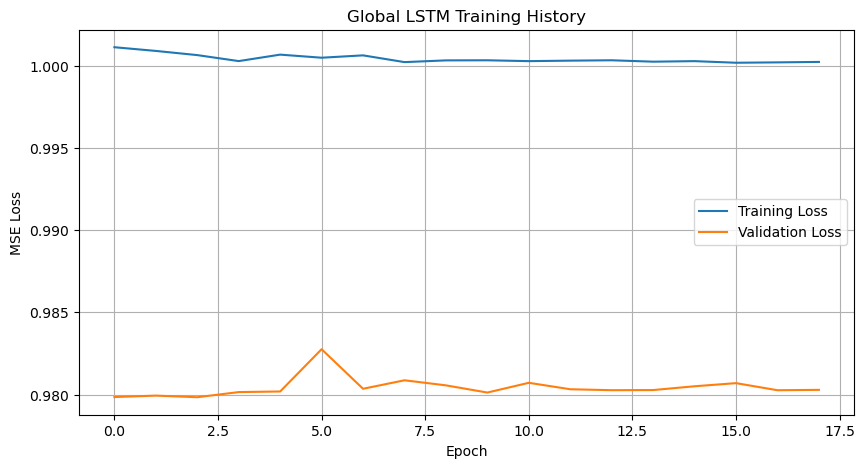

In [18]:
plt.figure(figsize=(10, 5))

plt.plot(
    history["train_loss"],
    label="Training Loss"
)

plt.plot(
    history["val_loss"],
    label="Validation Loss"
)

plt.title("Global LSTM Training History")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")

plt.legend()
plt.grid(True)
plt.show()

In [19]:
model.load_state_dict(
    torch.load(
        BEST_MODEL_PATH,
        map_location=DEVICE,
        weights_only=True
    )
)

model.eval()

print("Best Global LSTM model loaded.")

Best Global LSTM model loaded.


In [20]:
predictions = []

model.eval()

with torch.no_grad():

    for X_batch, y_batch in test_loader:

        X_batch = X_batch.to(DEVICE)

        pred = model(X_batch)

        predictions.append(
            pred.cpu().numpy()
        )

pred_scaled = np.concatenate(
    predictions,
    axis=0
).reshape(-1)

pred_original = scaler.inverse_transform(
    pred_scaled.reshape(-1, 1)
).flatten()

y_test_original = scaler.inverse_transform(
    y_test.reshape(-1, 1)
).flatten()

print("Prediction completed.")
print("Number of predictions:", len(pred_original))

Prediction completed.
Number of predictions: 4385


In [21]:
def calculate_smape(y_true, y_pred):

    denominator = (
        np.abs(y_true) + np.abs(y_pred)
    ) / 2

    denominator = np.maximum(
        denominator,
        1e-8
    )

    return np.mean(
        np.abs(y_true - y_pred) / denominator
    ) * 100


mae = mean_absolute_error(
    y_test_original,
    pred_original
)

rmse = np.sqrt(
    mean_squared_error(
        y_test_original,
        pred_original
    )
)

smape_value = calculate_smape(
    y_test_original,
    pred_original
)

print("Global LSTM Evaluation")
print("----------------------")
print(f"MAE:   {mae:.4f}")
print(f"RMSE:  {rmse:.4f}")
print(f"sMAPE: {smape_value:.2f}%")

Global LSTM Evaluation
----------------------
MAE:   63.0395
RMSE:  72.7703
sMAPE: 38.73%


In [22]:
prediction_df = pd.DataFrame({
    "Date": pd.to_datetime(date_test),
    "Destination": city_test,
    "Actual": y_test_original,
    "Predicted": pred_original
})

display(prediction_df.head(10))

,Date,Destination,Actual,Predicted
0,2013-08-07,Paris,257.000000,175.278854
1,2013-08-08,Paris,177.000000,175.353851
2,2013-08-09,Paris,73.000000,175.281357
3,2013-08-10,Paris,55.999996,175.080612
4,2013-08-11,Paris,123.000000,174.910110
5,2013-08-12,Paris,245.000000,174.881760
6,2013-08-13,Paris,111.000000,175.056229
7,2013-08-14,Paris,222.000000,175.019455
8,2013-08-15,Paris,66.999992,175.115952
9,2013-08-16,Paris,218.000000,174.991486


In [23]:
city_results = []

for city in CITIES:

    city_result = prediction_df[
        prediction_df["Destination"] == city
    ]

    actual = city_result["Actual"].values
    predicted = city_result["Predicted"].values

    city_mae = mean_absolute_error(
        actual,
        predicted
    )

    city_rmse = np.sqrt(
        mean_squared_error(
            actual,
            predicted
        )
    )

    city_smape = calculate_smape(
        actual,
        predicted
    )

    city_results.append({
        "Destination": city,
        "Samples": len(city_result),
        "MAE": city_mae,
        "RMSE": city_rmse,
        "sMAPE (%)": city_smape
    })

city_metrics = pd.DataFrame(city_results)

display(city_metrics)

,Destination,Samples,MAE,RMSE,sMAPE (%)
0,Paris,877,63.482166,72.940385,38.935883
1,Tokyo,877,64.274620,73.948799,39.656616
2,New York,877,61.473232,71.557952,38.203804
3,London,877,62.043072,71.666811,37.877781
4,Berlin,877,63.924381,73.703163,38.982784


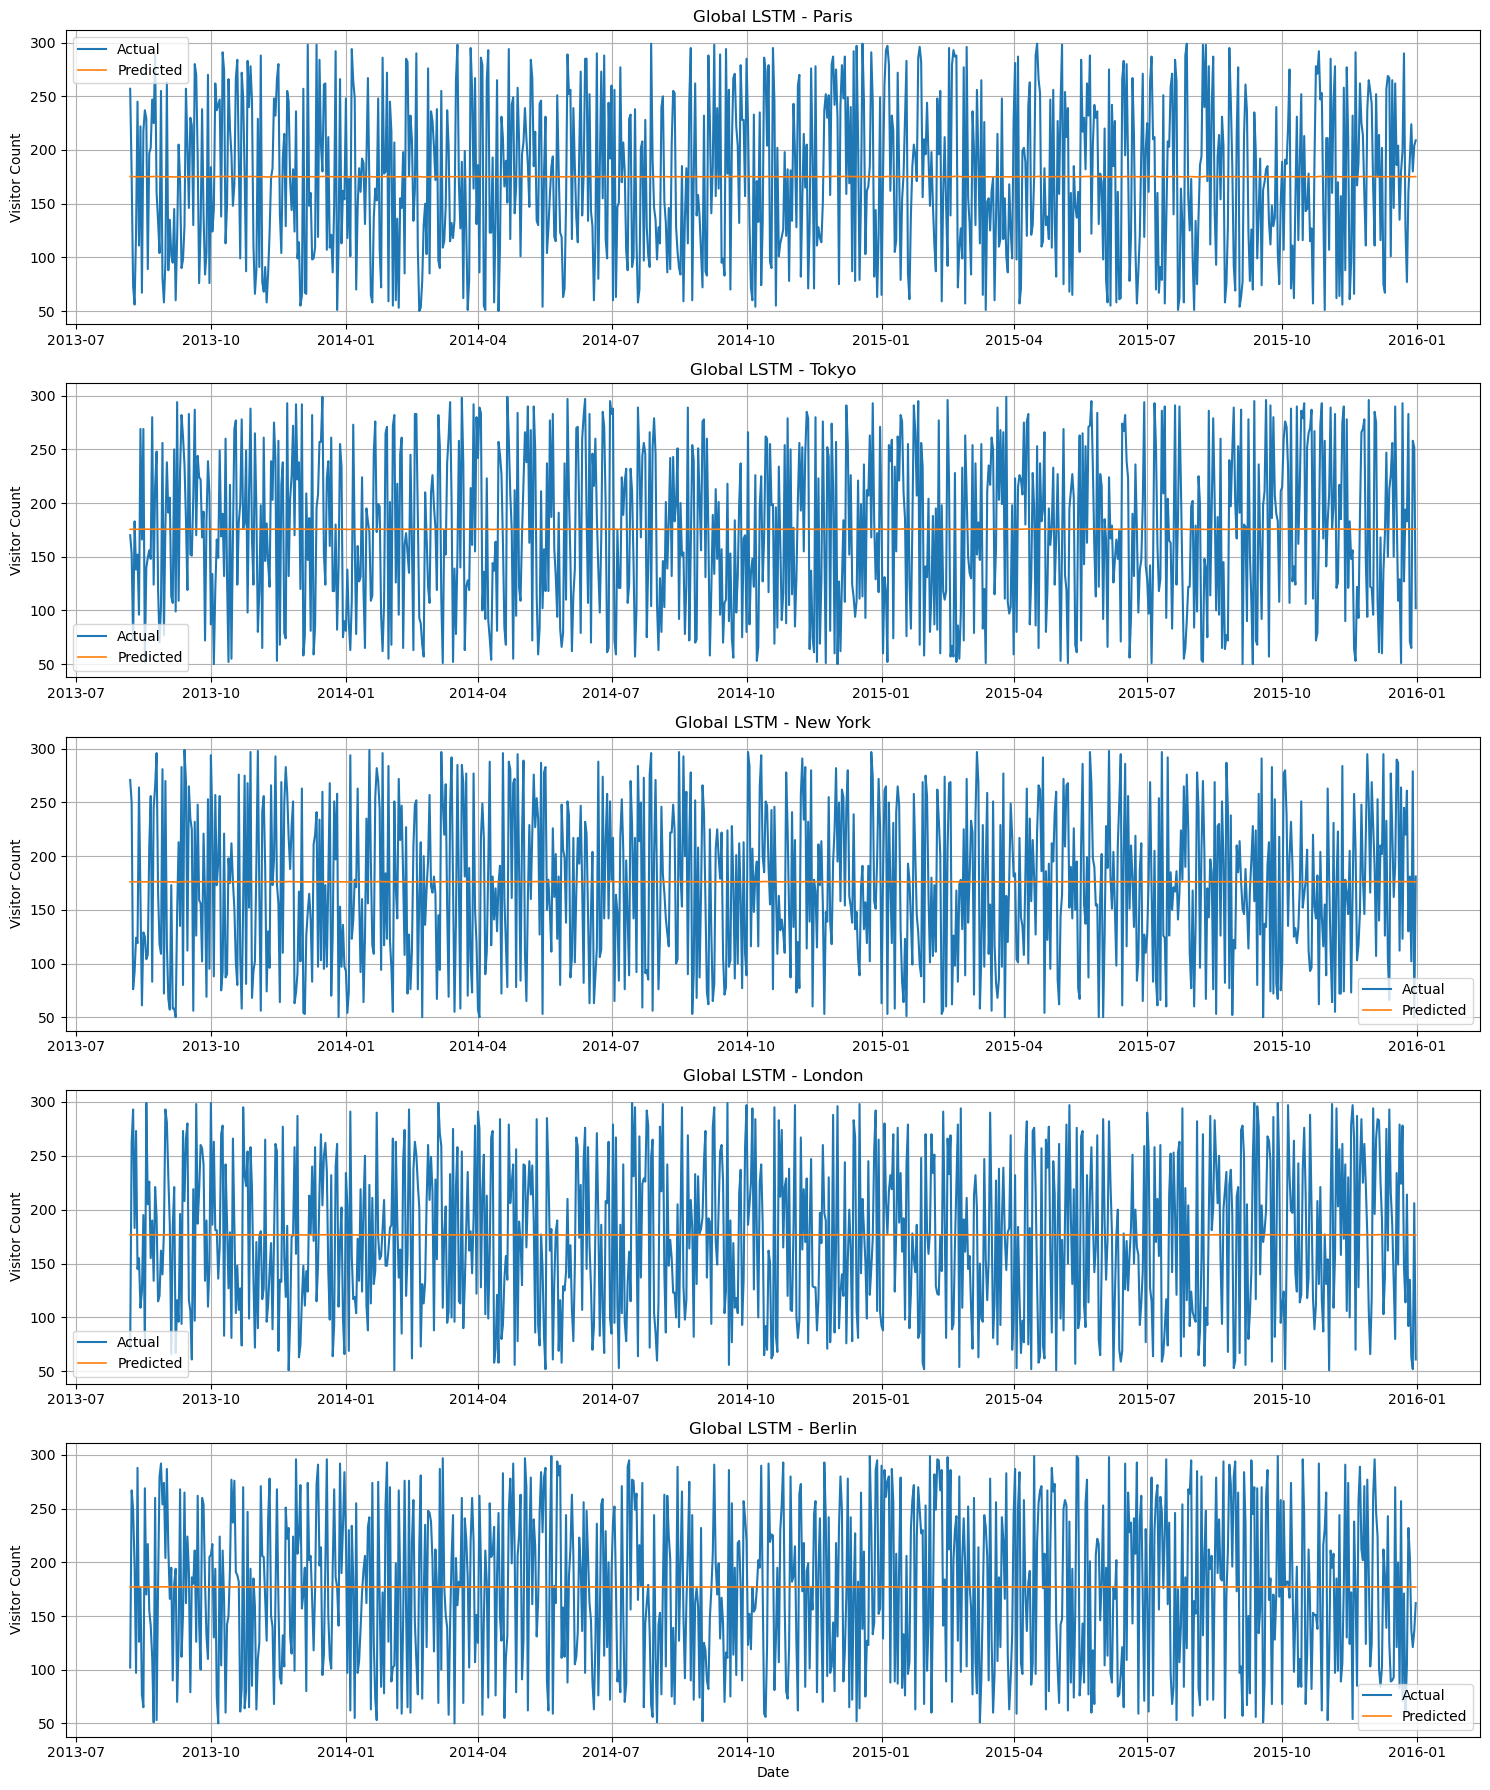

In [24]:
fig, axes = plt.subplots(
    len(CITIES),
    1,
    figsize=(15, 18)
)

for ax, city in zip(axes, CITIES):

    city_result = prediction_df[
        prediction_df["Destination"] == city
    ].sort_values("Date")

    ax.plot(
        city_result["Date"],
        city_result["Actual"],
        label="Actual",
        linewidth=1.5
    )

    ax.plot(
        city_result["Date"],
        city_result["Predicted"],
        label="Predicted",
        linewidth=1.2
    )

    ax.set_title(f"Global LSTM - {city}")
    ax.set_ylabel("Visitor Count")
    ax.legend()
    ax.grid(True)

axes[-1].set_xlabel("Date")

plt.tight_layout()
plt.show()

In [25]:
OUTPUT_DIR = Path("global_lstm_results")
OUTPUT_DIR.mkdir(exist_ok=True)

# Save model
torch.save(
    model.state_dict(),
    OUTPUT_DIR / "global_lstm.pth"
)

# Save scaler
joblib.dump(
    scaler,
    OUTPUT_DIR / "global_lstm_scaler.joblib"
)

# Save city mapping
joblib.dump(
    city_to_id,
    OUTPUT_DIR / "global_lstm_city_mapping.joblib"
)

# Save predictions
prediction_df.to_csv(
    OUTPUT_DIR / "global_lstm_predictions.csv",
    index=False
)

# Save city metrics
city_metrics.to_csv(
    OUTPUT_DIR / "global_lstm_city_metrics.csv",
    index=False
)

# Save overall metrics
overall_metrics = pd.DataFrame({
    "Model": ["Global LSTM"],
    "MAE": [mae],
    "RMSE": [rmse],
    "sMAPE (%)": [smape_value]
})

overall_metrics.to_csv(
    OUTPUT_DIR / "global_lstm_overall_metrics.csv",
    index=False
)

print("All files saved successfully.")
print("Output directory:", OUTPUT_DIR.resolve())

All files saved successfully.
Output directory: D:\Coding\thesis\global_lstm_results
